In [1]:
import sys
import h5py
import numpy as np
import scipy
import matplotlib.pyplot as plt
import healpy as hp

%matplotlib inline

NSIDE = 32
print(
    'Approximate resolution at NSIDE {} is {:.2} deg'.format(
        NSIDE, hp.nside2resol(NSIDE, arcmin=True) / 60
    )
)

NPIX = hp.nside2npix(NSIDE)
print(NPIX)
   
m = np.arange(NPIX)
hp.mollview(m, title="Mollview image RING")
hp.graticule()

In [2]:
filename = ( '/data/wiay/gw-data-releases/2026/19500064/'
    'samples-rpo4ab-1366933504-55469568-clipped.hdf') #shorthand to make finding the data easier, long path is a pain to work with 

I've changed how this cell runs to use array slicing instead of the really big for loop. Still shows an inhomogeneous distribution but I'm pretty sure this is due to the hopeless SNR cutoff already being imposed.

In [ ]:
nside = 32 #mediocre number of pixels, good for first pass but I'd like to increase as the project continues 
npix = hp.nside2npix(nside) # this gives the number of pixels on the map (far as i can tell)
chunk_size = 500_000 #everything I tried last week was taking too long so im splitting it into chunks to make it more manageable
snr_cut = 11.0
counts = np.zeros(npix, dtype=np.float64) #this line makes an empty array of pixels that will update as events fall into them, which i can call on later once its full (NEWLY CHANGED TO FLOAT FOR WHEN I START TO INCLUDE WEIGHTING)

with h5py.File(filename, 'r') as f:  #reading in the file and making sure I dont read every row at once and blow up my computer
    events = f['events'] #shorthand again
    ra = events.fields('right_ascension')[:]
    dec = events.fields('declination')[:]
    snr = events.fields('gstlal_rec_snr_net')[:]
    valid = np.isfinite(ra) & np.isfinite(dec) & np.isfinite(snr) & (snr >= snr_cut)
    pixels = hp.ang2pix(nside, np.pi/2 - dec[valid], ra[valid], lonlat = False)
    counts = np.bincount(pixels, minlength=npix)

hp.mollview(
    counts,
    title='GW event counts per HEALPix pixel with SNR cut of 11 using gstlal SNR',
    unit='Number of events',
    cmap='inferno'
)
plt.show()


IGNORE THIS CELL FOR THE MOMENT ITS NOT ANY USE 


nside = 128 #mediocre number of pixels, good for first pass but I'd like to increase as the project continues 
npix = hp.nside2npix(nside) # this gives the number of pixels on the map (far as i can tell)
chunk_size = 10_000 #everything I tried last week was taking too long so im splitting it into chunks to make it more manageable

snr_sum = np.zeros(npix, dtype=np.float64)
snr_count = np.zeros(npix, dtype=np.int64) #this line makes an empty array of pixels that will update as events fall into them, which i can call on later once its full 



with h5py.File(filename, 'r') as f:  #reading in the file and making sure I dont read every row at once and blow up my computer
    events = f['events'] #shorthand again
    n_events = len(events) # defining number of events

    for start in range(0, n_events, chunk_size): #making sure it only goes one chunk at a time 
        stop = min(start + chunk_size, n_events)

        ra = events['right_ascension'][start:stop] #defining what columns to look at  
        dec = events['declination'][start:stop]
        snr = events['gstlal_rec_snr_net'][start:stop]

        valid = np.isfinite(ra) & np.isfinite(dec) & np.isfinite(snr) #this just checks that the coordinate isnt nonsense
        ra = ra[valid]
        dec = dec[valid]
        snr = snr[valid]

        chunk_mean_snr = np.mean(snr) if len(snr) > 0 else np.nan
        
        print(
            f"Chunk {start:,}–{stop:,}: "
            f"mean SNR = {chunk_mean_snr:.3f}, "
            f"valid injections = {len(snr):,}"
    )

        ra_deg = np.rad2deg(ra) #converting radians to degrees (documentation says its given in radians so needs changed for Healpy)
        dec_deg = np.rad2deg(dec)

        pixels = hp.ang2pix( #this is changing these coordinates into pixel information so healpy knows how to plot it, using nside and my coordinates
            nside,
            ra_deg,
            dec_deg,
            lonlat=True
        )    

        snr_sum += np.bincount( #totals the SNR per pixel 
            pixels,
            weights = snr,
            minlength = npix
    )

        snr_count += np.bincount( #this counts the number of injections per pixel 
        pixels,
        minlength=npix
    )

mean_snr = np.divide( #uses previous 2 lines of code to find the mean per pixel 
    snr_sum,
    snr_count,
    out=np.full(npix, np.nan),
    where=snr_count > 0
)

mean_snr_plot = mean_snr.copy()
mean_snr_plot[snr_count == 0] = hp.UNSEEN #deals with any invalid SNR values 


hp.mollview(
    mean_snr_plot,
    title='Mean Recovered SNR per HEALPix Pixel',
    unit='Mean Recovered SNR',
    cmap='inferno'
)

plt.show()


**Next cell is plotting the histogram of sin of the declination, which I have read should be flat for a uniform distribution in colatitude**

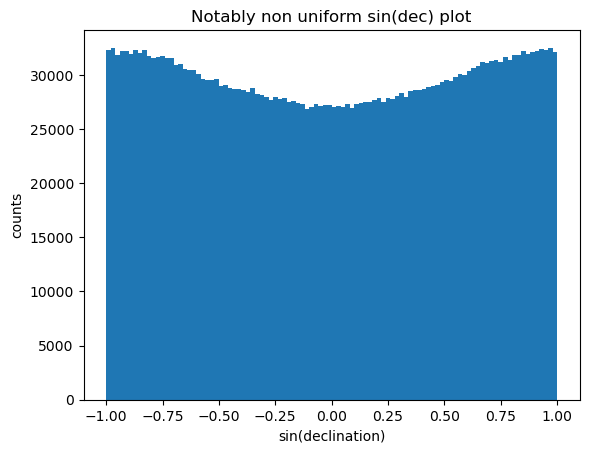

In [17]:
plt.hist(np.sin(dec), bins=100)
plt.title('Notably non uniform sin(dec) plot')
plt.xlabel('sin(declination)')
plt.ylabel('counts')


plt.show()

In [18]:
with h5py.File(filename, 'r') as f:  #reading in the file and making sure I dont read every row at once and blow up my computer
    events = f['events'] #shorthand again
    n_events = len(events)
    total = f.attrs['total_generated']
    accept = f.attrs['num_accepted']

print(total)
print(accept)
print(len(events))

870454872
8827136
2959534


Following cell is the code given in the appendix of the injections paper, not particularly useful for right now in terms of what it does but what its showing may prove useful in the coming weeks   


In [ ]:

#–––
# load the required data
with h5py.File(filename, 'r') as obj:
    events = obj['events'][:]
    meta = dict(obj.attrs.items())
#–––
# extract weights for mixture model
# see Essick, Research Notes of the AAS 5, 220 (2021).
weights = events['weights']
#–––
# extract p(m1, m2|draw)
pdraw = np.exp(events['lnpdraw_mass1_source']\
+ events['lnpdraw_mass2_source_GIVEN_mass1_source'])
# compute target distribution: flat in component masses between 10–20 Msun
# Note that we must include the proper normalization.
m1 = events['mass1_source']
m2 = events['mass2_source']
ptarget = (10 <= m1)*(m1 < 20)*(10 <= m2)*(m2 < 20) / (20-10)**2 / 2
#–––
### identify which events were detected using a FAR threshold
min_far = np.min([events["%s_far"%search] for search in \
meta["searches"]], axis=0)
detected = min_far < 1.0 # /year
### compute the Monte Carlo sum
pdet = np.sum(weights[detected] * ptarget[detected] / pdraw[detected]) \
/ meta["total_generated"]

# This is an example of how to compute detection efficiency for population over source frame component masses, taking injected distribution for every other parameter

This next cell was a test to see if the injections were definitely drawn isotropically, making sure that the way I have plotted it is definitely not the issue. Uses np.allclose to check that the log draw declination is equal to the cos(dec) which is indicative of an isotropic distribution 

In [15]:
with h5py.File(filename, 'r') as f:
    ev = f['events']
    dec = ev['declination'][:]
    lnp = ev['lnpdraw_declination'][:]
print(np.allclose(np.exp(lnp), np.cos(dec)/2))

True


## SNR cutoff

In [40]:
with h5py.File(filename, 'r') as f: 
    ev = f['events']
    snr = ev['pycbc_rec_snr_net']


In [41]:
print(np.nanmin(snr))

5.500005722045898


In [42]:
nanvalueentry = np.isnan(snr).sum()

In [43]:
realvalueentry = (snr >= np.nanmin(snr)).sum()

In [44]:
totalentries = nanvalueentry + realvalueentry 
print(totalentries - len(ev))

0


In [45]:
nanfraction = nanvalueentry/totalentries
print(nanfraction)

0.3148624073925152


This isn't ideal, about 38% of the data I have has a nan value for snr in this column (gstlal), I'm not sure if this is specific to this snr 'type' although the documentation doesnt actually tell you anything about what each different one is. (Apparently these are search pipelines)

Update: I have just ran for mbta and the nan amount in this column is 68%, going to try the third column and hope that this totals to 100, giving the full recovered from all 3 all have viable SNRs that just dont overlap at all --> So far both have had an approximate SNR cutoff of 7 

Not quite, ran the third and it has 31% nan values. Maybe this means some of them have been detected by more than one detector? (Nope realising this is by pipeline) frustratingly this third one also clearly has a lower SNR cutoff of 5.5 at its lowest. Ive found all of these using the network SNRs instead of by independent detector. 

Having checked min SNR for all of these (other than cbw) the min SNR came from pycbc giving a hopeless cutoff of 5 maybe? all the others gave minima of around 7 so I'm not sure why this one has been truncated differently?

## False Alarm Rate 

In [3]:
with h5py.File(filename, 'r') as f:
    ev = f['events']
    gstfar = ev['gstlal_far']
    mbtafar = ev['mbta_far']
    pycbcfar = ev['pycbc_far']


In [61]:
print('The mean (finite) false alarm rate for gst_lal is ', np.mean(np.isfinite(gstfar)), '(1/year)')
print('The mean (finite) false alarm rate for mbta is ', np.mean(np.isfinite(mbtafar)), '(1/year)')
print('The mean (finite) false alarm rate for pycbc is ', np.mean(np.isfinite(pycbcfar)), '(1/year)')



The mean (finite) false alarm rate for gst_lal is  0.6188484403287815 (1/year)
The mean (finite) false alarm rate for mbta is  0.318610970510898 (1/year)
The mean (finite) false alarm rate for pycbc is  0.6851375926074849 (1/year)


Just based on mean finite values the lowest false alarm rate goes for mbta, cosmology group uses 0.25 so none of these are really that great?

I have taken mbta to be the search pipeline with the best false alarm rate, and in turn used that in my plot at the top of the notebook which now has an imposed SNR cut of 10. The SNRs used were the mbta results with the cut imposed, previously this cut was the hopeless cut (at SNR = 7 for this pipeline). This has reduced the amount of events per pixel drastically.  

## Better estimation of FAR

In [18]:
far_fields = [
    'gstlal_far',
    'mbta_far',
    'pycbc_far'
]

with h5py.File(filename, 'r') as obj:
    events = obj['events']

    for field in far_fields:
        far = events[field][:]

        finite_far = far[np.isfinite(far)]

        print(f'\n{field}')
        print(f'Finite measurements: {len(finite_far)}')
        print(f'Median FAR: {np.median(finite_far):.6g} /year')
    



gstlal_far
Finite measurements: 1831503
Median FAR: 1.566 /year

mbta_far
Finite measurements: 942940
Median FAR: 0.0459382 /year

pycbc_far
Finite measurements: 2027688
Median FAR: 30.1638 /year


In [15]:
thresholds = [1.0, 0.25, 0.1, 0.01]

with h5py.File(filename, 'r') as obj:
    events = obj['events']
    n_events = len(events)

    for field in far_fields:
        far = events[field][:]

        print(f'\n{field}')

        for threshold in thresholds:
            passed = np.isfinite(far) & (far <= threshold)

            fraction = np.sum(passed) / n_events

            print(
                f'FAR <= {threshold:g} /year: '
                f'{fraction:.2%} ({np.sum(passed):,} records)'
            )


gstlal_far
FAR <= 1 /year: 30.13% (891,817 records)
FAR <= 0.25 /year: 27.95% (827,249 records)
FAR <= 0.1 /year: 26.59% (787,082 records)
FAR <= 0.01 /year: 23.61% (698,853 records)

mbta_far
FAR <= 1 /year: 21.41% (633,700 records)
FAR <= 0.25 /year: 18.69% (553,014 records)
FAR <= 0.1 /year: 17.11% (506,430 records)
FAR <= 0.01 /year: 13.87% (410,392 records)

pycbc_far
FAR <= 1 /year: 27.71% (820,004 records)
FAR <= 0.25 /year: 25.56% (756,534 records)
FAR <= 0.1 /year: 24.27% (718,221 records)
FAR <= 0.01 /year: 21.34% (631,462 records)


Based on medians - mbta still best for FAR HOWEVER gstlal has the highest fraction under the cosmology groups 0.25 threshold